In [1]:
# import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


In [7]:
# Configure project and dataset paths

PROJECT_ROOT = Path.cwd().parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "olist"

sellers_path = RAW_DATA_PATH / "olist_sellers_dataset.csv"
order_items_path = RAW_DATA_PATH / "olist_order_items_dataset.csv"
orders_path = RAW_DATA_PATH / "olist_orders_dataset.csv"

print("Dataset directory:", RAW_DATA_PATH)
print("\nFile verification:")

for file_path in [sellers_path, order_items_path, orders_path]:
    print(file_path.name, ":", "Found" if file_path.exists() else "Missing")

Dataset directory: d:\digitalTwin\data\raw\olist

File verification:
olist_sellers_dataset.csv : Found
olist_order_items_dataset.csv : Found
olist_orders_dataset.csv : Found


In [8]:
# Load datasets

sellers_df = pd.read_csv(sellers_path)
order_items_df = pd.read_csv(order_items_path)
orders_df = pd.read_csv(orders_path)

print("All datasets loaded successfully.")

All datasets loaded successfully.


In [9]:
# Dataset dimensions

datasets = {
    "Sellers": sellers_df,
    "Order Items": order_items_df,
    "Orders": orders_df
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Sellers
Rows: 3095
Columns: 4

Order Items
Rows: 112650
Columns: 7

Orders
Rows: 99441
Columns: 8


In [10]:
# Schema inspection

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"{name.upper()} SCHEMA")
    print("="*50)

    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Non-Null Count": df.notnull().sum().values,
        "Null Count": df.isnull().sum().values
    }))


SELLERS SCHEMA


,Column,Data Type,Non-Null Count,Null Count
0,seller_id,object,3095,0
1,seller_zip_code_prefix,int64,3095,0
2,seller_city,object,3095,0
3,seller_state,object,3095,0



ORDER ITEMS SCHEMA


,Column,Data Type,Non-Null Count,Null Count
0,order_id,object,112650,0
1,order_item_id,int64,112650,0
2,product_id,object,112650,0
3,seller_id,object,112650,0
4,shipping_limit_date,object,112650,0
5,price,float64,112650,0
6,freight_value,float64,112650,0



ORDERS SCHEMA


,Column,Data Type,Non-Null Count,Null Count
0,order_id,object,99441,0
1,customer_id,object,99441,0
2,order_status,object,99441,0
3,order_purchase_timestamp,object,99441,0
4,order_approved_at,object,99281,160
5,order_delivered_carrier_date,object,97658,1783
6,order_delivered_customer_date,object,96476,2965
7,order_estimated_delivery_date,object,99441,0


In [11]:
# Missing value analysis

for name, df in datasets.items():

    print(f"\n{name.upper()}")

    missing_report = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().sum() / len(df) * 100
        ).round(2)
    })

    display(missing_report)


SELLERS


,Missing Count,Missing Percentage
seller_id,0,0.00
seller_zip_code_prefix,0,0.00
seller_city,0,0.00
seller_state,0,0.00



ORDER ITEMS


,Missing Count,Missing Percentage
order_id,0,0.00
order_item_id,0,0.00
product_id,0,0.00
seller_id,0,0.00
shipping_limit_date,0,0.00
price,0,0.00
freight_value,0,0.00



ORDERS


,Missing Count,Missing Percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


In [12]:
# Primary key validation

key_checks = {
    "Sellers": {
        "data": sellers_df,
        "key": ["seller_id"]
    },
    "Orders": {
        "data": orders_df,
        "key": ["order_id"]
    },
    "Order Items": {
        "data": order_items_df,
        "key": ["order_id", "order_item_id"]
    }
}

for name, details in key_checks.items():

    df = details["data"]
    key = details["key"]

    duplicate_count = df.duplicated(subset=key).sum()

    print(f"\n{name}")
    print("Primary key:", key)
    print("Duplicate key records:", duplicate_count)
    print("Unique key:", duplicate_count == 0)


Sellers
Primary key: ['seller_id']
Duplicate key records: 0
Unique key: True

Orders
Primary key: ['order_id']
Duplicate key records: 0
Unique key: True

Order Items
Primary key: ['order_id', 'order_item_id']
Duplicate key records: 0
Unique key: True


In [13]:
# Seller foreign key validation

seller_ids = set(sellers_df["seller_id"])
order_item_seller_ids = set(order_items_df["seller_id"])

valid_seller_ids = seller_ids.intersection(order_item_seller_ids)

invalid_seller_ids = order_item_seller_ids - seller_ids

print("Unique sellers in master table:", len(seller_ids))
print("Unique sellers referenced in order items:", len(order_item_seller_ids))
print("Valid seller references:", len(valid_seller_ids))
print("Invalid seller references:", len(invalid_seller_ids))

print("\nForeign key integrity:",
      "PASSED" if len(invalid_seller_ids) == 0 else "FAILED")

Unique sellers in master table: 3095
Unique sellers referenced in order items: 3095
Valid seller references: 3095
Invalid seller references: 0

Foreign key integrity: PASSED


In [14]:
# Seller geographical analysis

print("Total sellers:", sellers_df["seller_id"].nunique())

print("Unique seller cities:", sellers_df["seller_city"].nunique())

print("Unique seller states:", sellers_df["seller_state"].nunique())

print("\nSeller distribution by state:")

state_distribution = (
    sellers_df.groupby("seller_state")
    .agg(
        seller_count=("seller_id", "nunique"),
        city_count=("seller_city", "nunique")
    )
    .sort_values("seller_count", ascending=False)
)

display(state_distribution)

print("\nTop 10 seller cities:")

city_distribution = (
    sellers_df.groupby(["seller_state", "seller_city"])
    .agg(seller_count=("seller_id", "nunique"))
    .sort_values("seller_count", ascending=False)
    .head(10)
)

display(city_distribution)

Total sellers: 3095
Unique seller cities: 611
Unique seller states: 23

Seller distribution by state:


,seller_count,city_count
seller_state,,
SP,1849,261
PR,349,67
MG,244,82
SC,190,65
RJ,171,38
RS,129,51
GO,40,12
DF,30,3
ES,23,11



Top 10 seller cities:


seller_count
seller_state seller_city                 
SP           sao paulo                694
PR           curitiba                 124
RJ           rio de janeiro            93
MG           belo horizonte            66
SP           ribeirao preto            52
             guarulhos                 50
             ibitinga                  49
             santo andre               45
             campinas                  41
PR           maringa                   40

In [15]:
# Seller-level commercial performance

seller_performance = (
    order_items_df
    .groupby("seller_id")
    .agg(
        total_order_items=("order_item_id", "count"),
        distinct_orders=("order_id", "nunique"),
        distinct_products=("product_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

# Display top 10 sellers by merchandise value

top_sellers = seller_performance.sort_values(
    by="merchandise_value",
    ascending=False
).head(10)

display(top_sellers)

,seller_id,total_order_items,distinct_orders,distinct_products,merchandise_value,freight_value,average_item_price
857,4869f7a5dfa277a7dca6462dcf3b52b2,1156,1132,95,"229,472.63","20,168.07",198.51
1013,53243585a1d6dc2643021fd1853d8905,410,358,23,"222,776.05","13,080.63",543.36
881,4a3ca9315b744ce9f8e9374361493884,1987,1806,399,"200,472.92","35,067.04",100.89
3024,fa1c13f2614d7b5c4749cbc52fecda94,586,585,289,"194,042.03","10,042.70",331.13
1535,7c67e1448b00f6e969d365cea6b010ab,1364,982,198,"187,923.89","51,612.55",137.77
1560,7e93a43ef30c4f03f38b393420bc753a,340,336,186,"176,431.87","6,322.18",518.92
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,1314,222,"160,236.57","24,955.75",103.31
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,1160,149,"141,745.53","20,902.85",121.05
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,915,154,"138,968.55","33,892.14",97.32
1824,955fee9216a65b617aa5c0531780ce60,1499,1287,104,"135,171.70","25,430.98",90.17


In [16]:
# Seller contribution to total merchandise value

total_merchandise_value = seller_performance[
    "merchandise_value"
].sum()

seller_performance["sales_contribution_pct"] = (
    seller_performance["merchandise_value"]
    / total_merchandise_value
) * 100

top_sellers = seller_performance.sort_values(
    by="merchandise_value",
    ascending=False
).head(10)

display(
    top_sellers[
        [
            "seller_id",
            "merchandise_value",
            "sales_contribution_pct",
            "distinct_orders",
            "total_order_items"
        ]
    ]
)

print("Total merchandise value:",
      round(total_merchandise_value, 2))

,seller_id,merchandise_value,sales_contribution_pct,distinct_orders,total_order_items
857,4869f7a5dfa277a7dca6462dcf3b52b2,"229,472.63",1.69,1132,1156
1013,53243585a1d6dc2643021fd1853d8905,"222,776.05",1.64,358,410
881,4a3ca9315b744ce9f8e9374361493884,"200,472.92",1.47,1806,1987
3024,fa1c13f2614d7b5c4749cbc52fecda94,"194,042.03",1.43,585,586
1535,7c67e1448b00f6e969d365cea6b010ab,"187,923.89",1.38,982,1364
1560,7e93a43ef30c4f03f38b393420bc753a,"176,431.87",1.30,336,340
2643,da8622b14eb17ae2831f4ac5b9dab84a,"160,236.57",1.18,1314,1551
1505,7a67c85e85bb2ce8582c35f2203ad736,"141,745.53",1.04,1160,1171
192,1025f0e2d44d7041d6cf58b6550e0bfa,"138,968.55",1.02,915,1428
1824,955fee9216a65b617aa5c0531780ce60,"135,171.70",0.99,1287,1499


Total merchandise value: 13591643.7


In [17]:
# Merge order items with order information

seller_transactions = order_items_df.merge(
    orders_df[[
        "order_id",
        "order_purchase_timestamp",
        "order_status"
    ]],
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Order-item records:", len(order_items_df))
print("Merged records:", len(seller_transactions))

print("\nMerge validation:")
print(seller_transactions["_merge"].value_counts())

print("\nMissing purchase timestamps:",
      seller_transactions["order_purchase_timestamp"].isna().sum())

Order-item records: 112650
Merged records: 112650

Merge validation:
_merge
both          112650
left_only          0
right_only         0
Name: count, dtype: int64

Missing purchase timestamps: 0


In [18]:
# Convert purchase timestamp into datetime

seller_transactions["order_purchase_timestamp"] = pd.to_datetime(
    seller_transactions["order_purchase_timestamp"],
    errors="coerce"
)

# Extract monthly period

seller_transactions["purchase_month"] = (
    seller_transactions["order_purchase_timestamp"]
    .dt.to_period("M")
)

print("Invalid purchase timestamps:",
      seller_transactions["purchase_month"].isna().sum())

print("\nAvailable monthly range:")
print(seller_transactions["purchase_month"].min())
print(seller_transactions["purchase_month"].max())

Invalid purchase timestamps: 0

Available monthly range:
2016-09
2018-09


In [19]:
# Monthly seller performance

monthly_seller_performance = (
    seller_transactions
    .dropna(subset=["purchase_month"])
    .groupby(["purchase_month", "seller_id"])
    .agg(
        total_order_items=("order_item_id", "count"),
        distinct_orders=("order_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

display(monthly_seller_performance.head(10))

,purchase_month,seller_id,total_order_items,distinct_orders,merchandise_value,freight_value
0,2016-09,1554a68530182680ad5c8b042c3ab563,2,1,72.89,63.34
1,2016-09,a425f92c199eb576938df686728acd20,1,1,59.50,15.56
2,2016-09,ecccfa2bb93b34a3bf033cc5d1dcdc69,3,1,134.97,8.49
3,2016-10,011b0eaba87386a2ae96a7d32bb531d1,2,1,99.98,29.18
4,2016-10,01cf7e3d21494c41fb86034f2e714fa1,1,1,69.90,19.26
5,2016-10,024b564ae893ce8e9bfa02c10a401ece,6,1,467.40,157.80
6,2016-10,0307f7565ff85b299b6e5ef162b1b1a9,1,1,16.90,10.96
7,2016-10,0336182e1b3e92f029d5354832045fdf,2,1,29.80,17.57
8,2016-10,05ff92fedb5be47920fea08e501238b9,1,1,89.00,32.01
9,2016-10,066a6914e1ebf3ea95a216c73a986b91,1,1,79.90,11.38


In [20]:
# Aggregate all sellers by month

monthly_overall_performance = (
    monthly_seller_performance
    .groupby("purchase_month")
    .agg(
        active_sellers=("seller_id", "nunique"),
        total_order_items=("total_order_items", "sum"),
        total_orders=("distinct_orders", "sum"),
        merchandise_value=("merchandise_value", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

display(monthly_overall_performance)

,purchase_month,active_sellers,total_order_items,total_orders,merchandise_value,freight_value
0,2016-09,3,6,3,267.36,87.39
1,2016-10,143,363,312,"49,507.66","7,301.18"
2,2016-12,1,1,1,10.90,8.72
3,2017-01,227,955,793,"120,312.87","16,875.62"
4,2017-02,427,1951,1746,"247,303.02","38,977.60"
5,2017-03,499,3000,2646,"374,344.30","57,704.29"
6,2017-04,506,2684,2409,"359,927.23","52,495.01"
7,2017-05,583,4136,3692,"506,071.14","80,119.81"
8,2017-06,539,3583,3242,"433,038.60","69,924.44"
9,2017-07,606,4519,4037,"498,031.48","86,940.14"


In [21]:
# Correct monthly overall seller performance

monthly_overall_performance = (
    seller_transactions
    .dropna(subset=["purchase_month"])
    .groupby("purchase_month")
    .agg(
        active_sellers=("seller_id", "nunique"),
        total_order_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

display(monthly_overall_performance)

,purchase_month,active_sellers,total_order_items,total_orders,merchandise_value,freight_value
0,2016-09,3,6,3,267.36,87.39
1,2016-10,143,363,308,"49,507.66","7,301.18"
2,2016-12,1,1,1,10.90,8.72
3,2017-01,227,955,789,"120,312.87","16,875.62"
4,2017-02,427,1951,1733,"247,303.02","38,977.60"
5,2017-03,499,3000,2641,"374,344.30","57,704.29"
6,2017-04,506,2684,2391,"359,927.23","52,495.01"
7,2017-05,583,4136,3660,"506,071.14","80,119.81"
8,2017-06,539,3583,3217,"433,038.60","69,924.44"
9,2017-07,606,4519,3969,"498,031.48","86,940.14"


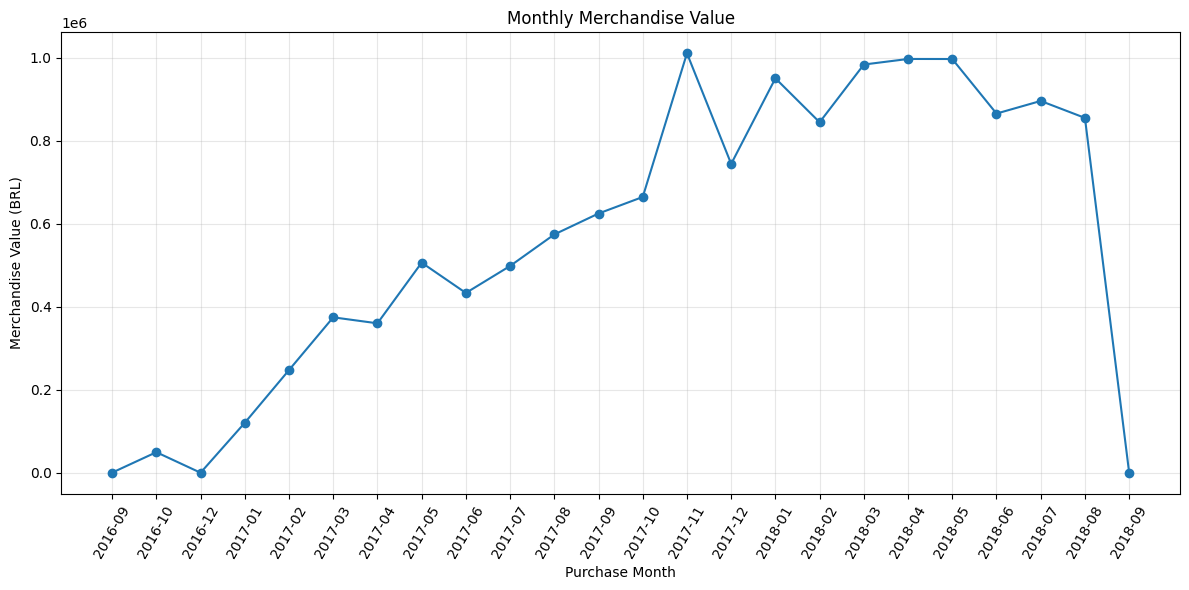

In [23]:
# Monthly merchandise value trend

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_overall_performance["purchase_month"].astype(str),
    monthly_overall_performance["merchandise_value"],
    marker="o"
)

plt.title("Monthly Merchandise Value")
plt.xlabel("Purchase Month")
plt.ylabel("Merchandise Value (BRL)")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Seller concentration analysis

seller_concentration = seller_performance[
    ["seller_id", "merchandise_value"]
].copy()

total_value = seller_concentration["merchandise_value"].sum()

seller_concentration = seller_concentration.sort_values(
    by="merchandise_value",
    ascending=False
).reset_index(drop=True)

seller_concentration["sales_share_pct"] = (
    seller_concentration["merchandise_value"] / total_value
) * 100

seller_concentration["cumulative_share_pct"] = (
    seller_concentration["sales_share_pct"].cumsum()
)

# Calculate concentration for selected seller groups

for n in [10, 50, 100]:
    share = seller_concentration.head(n)["sales_share_pct"].sum()
    print(f"Top {n} sellers contribution: {share:.2f}%")

# Herfindahl-Hirschman Index
hhi = (seller_concentration["sales_share_pct"] ** 2).sum()

print(f"\nSeller concentration HHI: {hhi:.2f}")

display(seller_concentration.head(10))

Top 10 sellers contribution: 13.15%
Top 50 sellers contribution: 32.89%
Top 100 sellers contribution: 45.06%

Seller concentration HHI: 35.69


,seller_id,merchandise_value,sales_share_pct,cumulative_share_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,"229,472.63",1.69,1.69
1,53243585a1d6dc2643021fd1853d8905,"222,776.05",1.64,3.33
2,4a3ca9315b744ce9f8e9374361493884,"200,472.92",1.47,4.80
3,fa1c13f2614d7b5c4749cbc52fecda94,"194,042.03",1.43,6.23
4,7c67e1448b00f6e969d365cea6b010ab,"187,923.89",1.38,7.61
5,7e93a43ef30c4f03f38b393420bc753a,"176,431.87",1.30,8.91
6,da8622b14eb17ae2831f4ac5b9dab84a,"160,236.57",1.18,10.09
7,7a67c85e85bb2ce8582c35f2203ad736,"141,745.53",1.04,11.13
8,1025f0e2d44d7041d6cf58b6550e0bfa,"138,968.55",1.02,12.16
9,955fee9216a65b617aa5c0531780ce60,"135,171.70",0.99,13.15


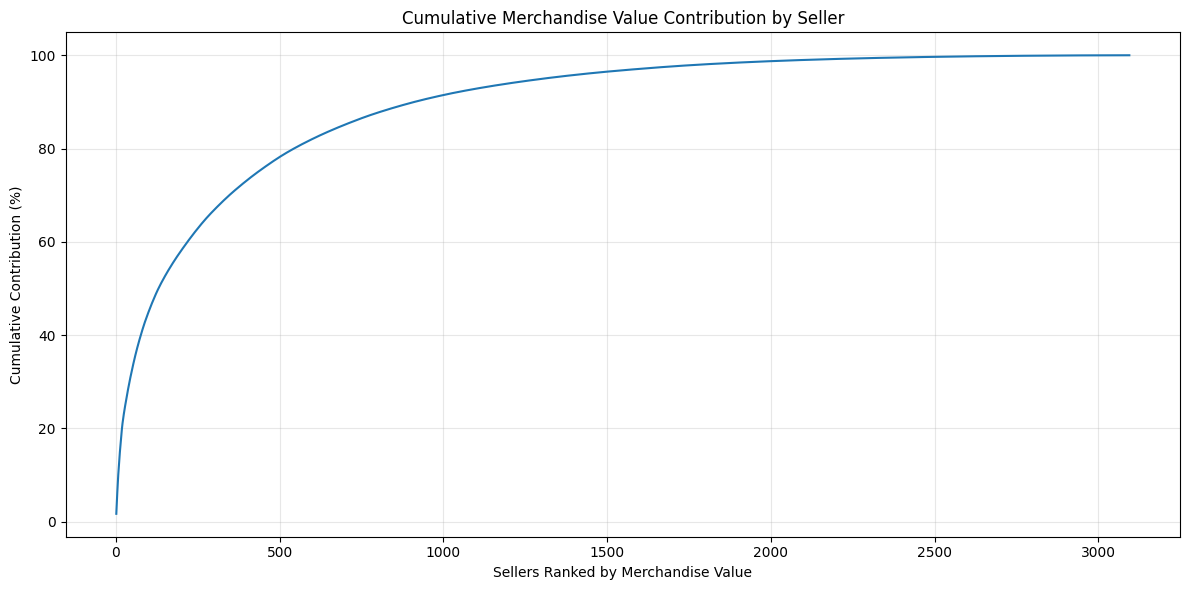

In [25]:
# Cumulative seller contribution

plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(seller_concentration) + 1),
    seller_concentration["cumulative_share_pct"]
)

plt.title("Cumulative Merchandise Value Contribution by Seller")
plt.xlabel("Sellers Ranked by Merchandise Value")
plt.ylabel("Cumulative Contribution (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Order status distribution

order_status_summary = (
    orders_df
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

order_status_summary["percentage"] = (
    order_status_summary["total_orders"]
    / order_status_summary["total_orders"].sum()
) * 100

display(order_status_summary)

print("Total orders:", orders_df["order_id"].nunique())

,order_status,total_orders,percentage
3,delivered,96478,97.02
6,shipped,1107,1.11
1,canceled,625,0.63
7,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
2,created,5,0.01
0,approved,2,0.00


Total orders: 99441


In [27]:
# Seller transaction performance by order status

seller_status_analysis = (
    seller_transactions
    .groupby("order_status")
    .agg(
        total_order_items=("order_item_id", "count"),
        distinct_orders=("order_id", "nunique"),
        active_sellers=("seller_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
    .sort_values("merchandise_value", ascending=False)
)

display(seller_status_analysis)

,order_status,total_order_items,distinct_orders,active_sellers,merchandise_value,freight_value
2,delivered,110197,96478,2970,"13,221,498.11","2,198,275.64"
5,shipped,1185,1106,499,"150,727.44","26,401.90"
1,canceled,542,461,329,"95,235.27","10,650.45"
3,invoiced,359,312,174,"61,526.37","7,462.38"
4,processing,357,301,204,"60,439.22","8,954.89"
6,unavailable,7,6,6,"2,007.69",132.80
0,approved,3,2,2,209.60,31.48


In [28]:
# Delivered order-item transactions

delivered_transactions = seller_transactions[
    seller_transactions["order_status"] == "delivered"
].copy()

delivered_seller_performance = (
    delivered_transactions
    .groupby("seller_id")
    .agg(
        delivered_order_items=("order_item_id", "count"),
        delivered_orders=("order_id", "nunique"),
        delivered_merchandise_value=("price", "sum"),
        associated_freight_value=("freight_value", "sum")
    )
    .reset_index()
    .sort_values(
        "delivered_merchandise_value",
        ascending=False
    )
)

display(delivered_seller_performance.head(10))

print(
    "Total delivered merchandise value:",
    round(delivered_seller_performance[
        "delivered_merchandise_value"
    ].sum(), 2)
)

,seller_id,delivered_order_items,delivered_orders,delivered_merchandise_value,associated_freight_value
834,4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,"226,987.93","20,019.13"
982,53243585a1d6dc2643021fd1853d8905,400,348,"217,940.44","12,856.58"
858,4a3ca9315b744ce9f8e9374361493884,1949,1772,"196,882.12","34,338.31"
2903,fa1c13f2614d7b5c4749cbc52fecda94,579,578,"190,917.14","9,916.36"
1480,7c67e1448b00f6e969d365cea6b010ab,1355,973,"186,570.05","51,236.64"
1504,7e93a43ef30c4f03f38b393420bc753a,322,319,"165,981.49","5,992.06"
2543,da8622b14eb17ae2831f4ac5b9dab84a,1548,1311,"159,816.87","24,889.91"
1450,7a67c85e85bb2ce8582c35f2203ad736,1155,1145,"139,658.69","20,619.83"
188,1025f0e2d44d7041d6cf58b6550e0bfa,1420,910,"138,208.56","33,716.40"
1758,955fee9216a65b617aa5c0531780ce60,1472,1261,"131,836.71","24,769.77"


Total delivered merchandise value: 13221498.11


In [29]:
# Seller delivery coverage

all_seller_ids = set(sellers_df["seller_id"])

delivered_seller_ids = set(
    delivered_transactions["seller_id"].unique()
)

sellers_without_delivered_orders = (
    all_seller_ids - delivered_seller_ids
)

seller_delivery_coverage = pd.DataFrame({
    "Category": [
        "Total registered sellers",
        "Sellers with delivered items",
        "Sellers without delivered items"
    ],
    "Count": [
        len(all_seller_ids),
        len(delivered_seller_ids),
        len(sellers_without_delivered_orders)
    ]
})

seller_delivery_coverage["Percentage"] = (
    seller_delivery_coverage["Count"]
    / len(all_seller_ids) * 100
).round(2)

display(seller_delivery_coverage)

,Category,Count,Percentage
0,Total registered sellers,3095,100.00
1,Sellers with delivered items,2970,95.96
2,Sellers without delivered items,125,4.04


In [31]:
# Seller and Order relationship validation

# Count order items associated with each seller
seller_item_counts = (
    order_items_df.groupby("seller_id")
    .size()
)

# Count order items associated with each order
order_item_counts = (
    order_items_df.groupby("order_id")
    .size()
)

# Check foreign key integrity
invalid_sellers = set(order_items_df["seller_id"]) - set(sellers_df["seller_id"])

invalid_orders = set(order_items_df["order_id"]) - set(orders_df["order_id"])

print("SELLER → ORDER ITEMS")
print("Registered sellers:", sellers_df["seller_id"].nunique())
print("Sellers referenced:", order_items_df["seller_id"].nunique())
print("Invalid seller references:", len(invalid_sellers))
print("Sellers with multiple order items:", (seller_item_counts > 1).sum())
print("Maximum order items per seller:", seller_item_counts.max())

print("\nORDER → ORDER ITEMS")
print("Registered orders:", orders_df["order_id"].nunique())
print("Orders with order items:", order_item_counts.size)
print("Orders without order items:",
      orders_df["order_id"].nunique() - order_item_counts.size)
print("Invalid order references:", len(invalid_orders))
print("Orders with multiple items:", (order_item_counts > 1).sum())
print("Maximum items per order:", order_item_counts.max())

SELLER → ORDER ITEMS
Registered sellers: 3095
Sellers referenced: 3095
Invalid seller references: 0
Sellers with multiple order items: 2586
Maximum order items per seller: 2033

ORDER → ORDER ITEMS
Registered orders: 99441
Orders with order items: 98666
Orders without order items: 775
Invalid order references: 0
Orders with multiple items: 9803
Maximum items per order: 21


In [32]:
# Build integrated seller-level state

seller_state = (
    sellers_df
    .merge(
        seller_performance,
        on="seller_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        delivered_seller_performance,
        on="seller_id",
        how="left",
        validate="one_to_one"
    )
)

# Fill missing delivered metrics with zero
delivered_columns = [
    "delivered_order_items",
    "delivered_orders",
    "delivered_merchandise_value",
    "associated_freight_value"
]

seller_state[delivered_columns] = (
    seller_state[delivered_columns].fillna(0)
)

print("Seller state constructed successfully.")
print("Total seller records:", len(seller_state))

display(seller_state.head())

Seller state constructed successfully.
Total seller records: 3095


,seller_id,seller_zip_code_prefix,seller_city,seller_state,total_order_items,distinct_orders,distinct_products,merchandise_value,freight_value,average_item_price,sales_contribution_pct,delivered_order_items,delivered_orders,delivered_merchandise_value,associated_freight_value
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,3,3,3,218.70,27.90,72.90,0.00,3.00,3.00,218.70,27.90
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,41,40,30,"11,703.07","1,438.73",285.44,0.09,40.00,39.00,"11,413.17","1,410.15"
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,1,1,1,158.00,16.21,158.00,0.00,1.00,1.00,158.00,16.21
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,1,1,1,79.99,15.66,79.99,0.00,1.00,1.00,79.99,15.66
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,1,1,1,167.99,31.93,167.99,0.00,1.00,1.00,167.99,31.93


In [33]:
# Validate seller state

print("Unique seller IDs:", seller_state["seller_id"].nunique())
print("Duplicate seller IDs:", seller_state["seller_id"].duplicated().sum())

print("\nMissing values:")
display(seller_state.isnull().sum())

print("\nSeller state dimensions:", seller_state.shape)

Unique seller IDs: 3095
Duplicate seller IDs: 0

Missing values:


seller_id                      0
seller_zip_code_prefix         0
seller_city                    0
seller_state                   0
total_order_items              0
distinct_orders                0
distinct_products              0
merchandise_value              0
freight_value                  0
average_item_price             0
sales_contribution_pct         0
delivered_order_items          0
delivered_orders               0
delivered_merchandise_value    0
associated_freight_value       0
dtype: int64


Seller state dimensions: (3095, 15)


In [34]:
# Seller state summary

total_sellers = seller_state["seller_id"].nunique()

sellers_with_deliveries = (
    seller_state["delivered_orders"] > 0
).sum()

sellers_without_deliveries = (
    seller_state["delivered_orders"] == 0
).sum()

print("SELLER MANAGEMENT STATE SUMMARY")
print("=" * 45)

print("Total sellers:", total_sellers)
print("Sellers with delivered orders:", sellers_with_deliveries)
print("Sellers without delivered orders:", sellers_without_deliveries)

print(
    "Total merchandise value:",
    round(seller_state["merchandise_value"].sum(), 2)
)

print(
    "Total delivered merchandise value:",
    round(seller_state["delivered_merchandise_value"].sum(), 2)
)

print(
    "Total freight value:",
    round(seller_state["freight_value"].sum(), 2)
)

print(
    "Total associated delivered freight:",
    round(seller_state["associated_freight_value"].sum(), 2)
)

SELLER MANAGEMENT STATE SUMMARY
Total sellers: 3095
Sellers with delivered orders: 2970
Sellers without delivered orders: 125
Total merchandise value: 13591643.7
Total delivered merchandise value: 13221498.11
Total freight value: 2251909.54
Total associated delivered freight: 2198275.64


In [35]:
# Seller Scenario Simulation

def simulate_seller_profit(
    selling_price,
    cost_price,
    freight_collected,
    freight_cost,
    commission_rate
):
    # Input validation
    if min(selling_price, cost_price, freight_collected, freight_cost) < 0:
        raise ValueError("Prices and freight values cannot be negative.")

    if not 0 <= commission_rate <= 1:
        raise ValueError("Commission rate must be between 0 and 1.")

    # Commission calculated on item selling price
    platform_commission = selling_price * commission_rate

    # Seller's estimated contribution after specified costs
    estimated_profit = (
        selling_price
        + freight_collected
        - cost_price
        - freight_cost
        - platform_commission
    )

    profit_margin = (
        estimated_profit / selling_price * 100
        if selling_price > 0 else 0
    )

    return {
        "selling_price": selling_price,
        "cost_price": cost_price,
        "freight_collected": freight_collected,
        "freight_cost": freight_cost,
        "platform_commission": platform_commission,
        "estimated_profit": estimated_profit,
        "profit_margin_pct": profit_margin
    }


# Example hypothetical scenario
scenario_1 = simulate_seller_profit(
    selling_price=750,
    cost_price=500,
    freight_collected=20,
    freight_cost=40,
    commission_rate=0.10
)

print("SELLER SCENARIO RESULT")
print("=" * 40)

for metric, value in scenario_1.items():
    print(f"{metric}: R$ {value:,.2f}")

SELLER SCENARIO RESULT
selling_price: R$ 750.00
cost_price: R$ 500.00
freight_collected: R$ 20.00
freight_cost: R$ 40.00
platform_commission: R$ 75.00
estimated_profit: R$ 155.00
profit_margin_pct: R$ 20.67


In [36]:
# Compare seller business scenarios

scenarios = {
    "Baseline": {
        "selling_price": 750,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 40,
        "commission_rate": 0.10
    },

    "Increased Cost": {
        "selling_price": 750,
        "cost_price": 550,
        "freight_collected": 20,
        "freight_cost": 40,
        "commission_rate": 0.10
    },

    "Reduced Selling Price": {
        "selling_price": 675,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 40,
        "commission_rate": 0.10
    },

    "Increased Freight": {
        "selling_price": 750,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 60,
        "commission_rate": 0.10
    }
}

scenario_results = []

for scenario_name, inputs in scenarios.items():

    result = simulate_seller_profit(**inputs)

    result["scenario"] = scenario_name

    scenario_results.append(result)

scenario_comparison = pd.DataFrame(scenario_results)

scenario_comparison = scenario_comparison[
    [
        "scenario",
        "selling_price",
        "cost_price",
        "freight_cost",
        "platform_commission",
        "estimated_profit",
        "profit_margin_pct"
    ]
]

display(scenario_comparison.round(2))

,scenario,selling_price,cost_price,freight_cost,platform_commission,estimated_profit,profit_margin_pct
0,Baseline,750,500,40,75.00,155.00,20.67
1,Increased Cost,750,550,40,75.00,105.00,14.00
2,Reduced Selling Price,675,500,40,67.50,87.50,12.96
3,Increased Freight,750,500,60,75.00,135.00,18.00


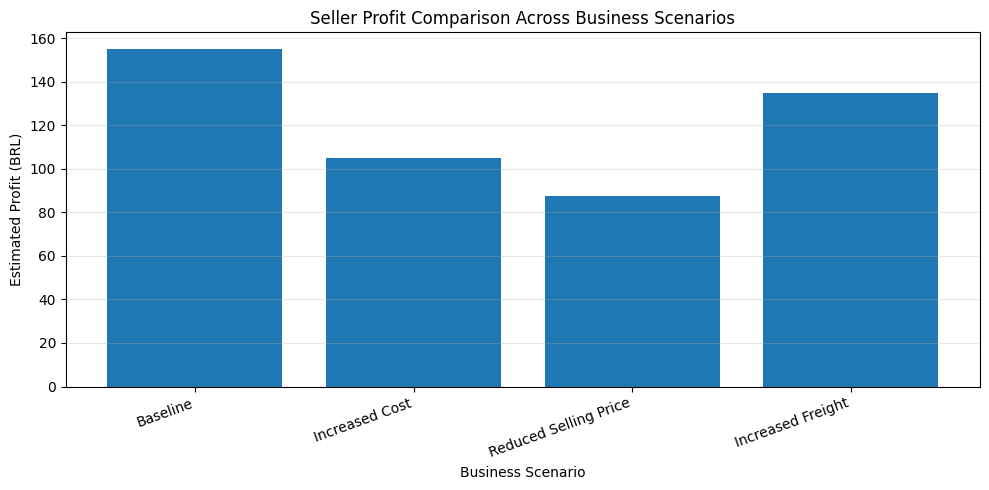

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    scenario_comparison["scenario"],
    scenario_comparison["estimated_profit"]
)

plt.title("Seller Profit Comparison Across Business Scenarios")
plt.xlabel("Business Scenario")
plt.ylabel("Estimated Profit (BRL)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# Test a loss-making business scenario

loss_scenario = simulate_seller_profit(
    selling_price=450,
    cost_price=500,
    freight_collected=20,
    freight_cost=40,
    commission_rate=0.10
)

print("LOSS DETECTION SCENARIO")
print("=" * 40)

for metric, value in loss_scenario.items():
    print(f"{metric}: R$ {value:,.2f}")

if loss_scenario["estimated_profit"] < 0:
    print("\nALERT: SELLER IS OPERATING AT A LOSS")

elif loss_scenario["estimated_profit"] == 0:
    print("\nBREAK-EVEN: NO PROFIT OR LOSS")

else:
    print("\nSTATUS: PROFITABLE")

LOSS DETECTION SCENARIO
selling_price: R$ 450.00
cost_price: R$ 500.00
freight_collected: R$ 20.00
freight_cost: R$ 40.00
platform_commission: R$ 45.00
estimated_profit: R$ -115.00
profit_margin_pct: R$ -25.56

ALERT: SELLER IS OPERATING AT A LOSS


In [39]:
# Seller Management Business Rules

seller_business_rules = {
    "SM01": "Every seller must have a unique seller_id.",
    "SM02": "Every order-item seller_id must reference a valid seller.",
    "SM03": "One seller can participate in multiple orders.",
    "SM04": "Seller-order relationships are established through order_items.",
    "SM05": "Merchandise value and freight value must be tracked separately.",
    "SM06": "Delivered performance must use delivered orders only.",
    "SM07": "Historical records must remain unchanged during scenario simulation.",
    "SM08": "Scenario cost and selling prices must be non-negative.",
    "SM09": "Platform commission must be between 0 and 100 percent.",
    "SM10": "Negative estimated profit must trigger a loss alert.",
    "SM11": "Zero estimated profit must trigger a break-even status.",
    "SM12": "Profit calculations must disclose all included and excluded costs."
}

for rule_id, description in seller_business_rules.items():
    print(f"{rule_id}: {description}")

SM01: Every seller must have a unique seller_id.
SM02: Every order-item seller_id must reference a valid seller.
SM03: One seller can participate in multiple orders.
SM04: Seller-order relationships are established through order_items.
SM05: Merchandise value and freight value must be tracked separately.
SM06: Delivered performance must use delivered orders only.
SM07: Historical records must remain unchanged during scenario simulation.
SM08: Scenario cost and selling prices must be non-negative.
SM09: Platform commission must be between 0 and 100 percent.
SM10: Negative estimated profit must trigger a loss alert.
SM11: Zero estimated profit must trigger a break-even status.
SM12: Profit calculations must disclose all included and excluded costs.


In [40]:
# Seller Management: Component Interface Definition

seller_component_interface = {
    "component_name": "Seller Management",

    "inputs": [
        "seller_id",
        "seller_location",
        "order_item_records",
        "product_id",
        "order_status",
        "purchase_timestamp",
        "selling_price",
        "cost_price",
        "freight_cost",
        "platform_commission_rate"
    ],

    "outputs": [
        "validated_seller_records",
        "seller_order_history",
        "seller_merchandise_value",
        "seller_freight_value",
        "seller_delivered_performance",
        "monthly_seller_performance",
        "estimated_seller_profit",
        "profit_margin",
        "profitability_alert"
    ],

    "dependencies": [
        "Product Management",
        "Order & Sales Management",
        "Payment & Revenue Management",
        "Central Simulation Engine"
    ]
}

print("SELLER MANAGEMENT COMPONENT INTERFACE")
print("=" * 50)

for key, value in seller_component_interface.items():
    print(f"\n{key.upper()}")

    if isinstance(value, list):
        for item in value:
            print(" -", item)
    else:
        print(value)

SELLER MANAGEMENT COMPONENT INTERFACE

COMPONENT_NAME
Seller Management

INPUTS
 - seller_id
 - seller_location
 - order_item_records
 - product_id
 - order_status
 - purchase_timestamp
 - selling_price
 - cost_price
 - freight_cost
 - platform_commission_rate

OUTPUTS
 - validated_seller_records
 - seller_order_history
 - seller_merchandise_value
 - seller_freight_value
 - seller_delivered_performance
 - monthly_seller_performance
 - estimated_seller_profit
 - profit_margin
 - profitability_alert

DEPENDENCIES
 - Product Management
 - Order & Sales Management
 - Payment & Revenue Management
 - Central Simulation Engine


In [41]:

# Seller Management Input Validation

import pandas as pd

validation_results = []

def record_check(rule_id, description, condition, details=""):
    validation_results.append({
        "rule_id": rule_id,
        "description": description,
        "status": "PASSED" if condition else "FAILED",
        "details": details
    })


# --------------------------------------------------
# 1. Required column validation
# --------------------------------------------------

required_columns = {
    "sellers_df": [
        "seller_id",
        "seller_zip_code_prefix",
        "seller_city",
        "seller_state"
    ],
    "order_items_df": [
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value"
    ],
    "orders_df": [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp"
    ]
}

dataframes = {
    "sellers_df": sellers_df,
    "order_items_df": order_items_df,
    "orders_df": orders_df
}

for df_name, columns in required_columns.items():
    missing_columns = [
        col for col in columns
        if col not in dataframes[df_name].columns
    ]

    record_check(
        "SCHEMA",
        f"{df_name} required columns",
        len(missing_columns) == 0,
        f"Missing columns: {missing_columns}"
    )


# --------------------------------------------------
# 2. Seller ID uniqueness (SM01)
# --------------------------------------------------

duplicate_seller_ids = sellers_df["seller_id"].duplicated().sum()

record_check(
    "SM01",
    "Every seller must have a unique seller_id",
    duplicate_seller_ids == 0,
    f"Duplicate seller IDs: {duplicate_seller_ids}"
)


# --------------------------------------------------
# 3. Seller foreign-key integrity (SM02)
# --------------------------------------------------

registered_sellers = set(sellers_df["seller_id"].dropna())
referenced_sellers = set(order_items_df["seller_id"].dropna())

invalid_seller_ids = referenced_sellers - registered_sellers

record_check(
    "SM02",
    "Every order-item seller_id must reference a valid seller",
    len(invalid_seller_ids) == 0,
    f"Invalid seller references: {len(invalid_seller_ids)}"
)


# --------------------------------------------------
# 4. Seller-to-order-item relationship (SM03, SM04)
# --------------------------------------------------

seller_item_counts = (
    order_items_df.groupby("seller_id")["order_id"].count()
)

multi_item_sellers = (seller_item_counts > 1).sum()

record_check(
    "SM03",
    "One seller can participate in multiple order items",
    multi_item_sellers > 0,
    f"Sellers with multiple order items: {multi_item_sellers}"
)

record_check(
    "SM04",
    "Seller-order relationships are established through order_items",
    "seller_id" in order_items_df.columns
    and "order_id" in order_items_df.columns,
    "Relationship is represented through seller_id and order_id"
)


# --------------------------------------------------
# 5. Merchandise and freight separation (SM05)
# --------------------------------------------------

record_check(
    "SM05",
    "Merchandise and freight values are tracked separately",
    "price" in order_items_df.columns
    and "freight_value" in order_items_df.columns,
    "Separate price and freight_value columns are available"
)


# --------------------------------------------------
# 6. Delivered performance validation (SM06)
# --------------------------------------------------

delivered_records = order_items_df.merge(
    orders_df[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

delivered_records = delivered_records[
    delivered_records["order_status"] == "delivered"
]

record_check(
    "SM06",
    "Delivered performance uses delivered orders only",
    delivered_records["order_status"].eq("delivered").all(),
    f"Delivered order-item records: {len(delivered_records)}"
)


# --------------------------------------------------
# 7. Scenario parameter validation (SM08, SM09)
# --------------------------------------------------

def validate_scenario_inputs(
    selling_price,
    cost_price,
    freight_collected,
    freight_cost,
    platform_commission_rate
):
    values = {
        "selling_price": selling_price,
        "cost_price": cost_price,
        "freight_collected": freight_collected,
        "freight_cost": freight_cost
    }

    for name, value in values.items():
        if not isinstance(value, (int, float)) or pd.isna(value):
            raise ValueError(f"{name} must be a valid number.")

        if value < 0:
            raise ValueError(f"{name} cannot be negative.")

    if not isinstance(platform_commission_rate, (int, float)):
        raise ValueError("Commission rate must be numeric.")

    if not 0 <= platform_commission_rate <= 1:
        raise ValueError(
            "Commission rate must be between 0 and 1 "
            "(0% to 100%)."
        )

    return True


# Example validation using the baseline scenario
scenario_valid = validate_scenario_inputs(
    selling_price=750,
    cost_price=500,
    freight_collected=20,
    freight_cost=40,
    platform_commission_rate=0.10
)

record_check(
    "SM08-SM09",
    "Scenario prices are non-negative and commission is within limits",
    scenario_valid,
    "Baseline scenario inputs validated"
)


# --------------------------------------------------
# 8. Display validation report
# --------------------------------------------------

validation_df = pd.DataFrame(validation_results)

print("SELLER MANAGEMENT VALIDATION REPORT")
print("=" * 65)

display(validation_df)

print("\nValidation summary:")
print(validation_df["status"].value_counts())


SELLER MANAGEMENT VALIDATION REPORT


,rule_id,description,status,details
0,SCHEMA,sellers_df required columns,PASSED,Missing columns: []
1,SCHEMA,order_items_df required columns,PASSED,Missing columns: []
2,SCHEMA,orders_df required columns,PASSED,Missing columns: []
3,SM01,Every seller must have a unique seller_id,PASSED,Duplicate seller IDs: 0
4,SM02,Every order-item seller_id must reference a va...,PASSED,Invalid seller references: 0
5,SM03,One seller can participate in multiple order i...,PASSED,Sellers with multiple order items: 2586
6,SM04,Seller-order relationships are established thr...,PASSED,Relationship is represented through seller_id ...
7,SM05,Merchandise and freight values are tracked sep...,PASSED,Separate price and freight_value columns are a...
8,SM06,Delivered performance uses delivered orders only,PASSED,Delivered order-item records: 110197
9,SM08-SM09,Scenario prices are non-negative and commissio...,PASSED,Baseline scenario inputs validated



Validation summary:
status
PASSED    10
Name: count, dtype: int64


In [42]:

# Seller Management Scenario Engine

def calculate_seller_profit(
    selling_price,
    cost_price,
    freight_collected,
    freight_cost,
    platform_commission_rate
):
    validate_scenario_inputs(
        selling_price,
        cost_price,
        freight_collected,
        freight_cost,
        platform_commission_rate
    )

    platform_commission = (
        selling_price * platform_commission_rate
    )

    estimated_profit = (
        selling_price
        - cost_price
        + freight_collected
        - freight_cost
        - platform_commission
    )

    profit_margin_pct = (
        estimated_profit / selling_price * 100
        if selling_price > 0 else 0
    )

    if estimated_profit < 0:
        status = "LOSS ALERT"
    elif estimated_profit == 0:
        status = "BREAK-EVEN"
    else:
        status = "PROFITABLE"

    return {
        "selling_price": selling_price,
        "cost_price": cost_price,
        "freight_collected": freight_collected,
        "freight_cost": freight_cost,
        "platform_commission": platform_commission,
        "estimated_profit": estimated_profit,
        "profit_margin_pct": profit_margin_pct,
        "status": status
    }


# --------------------------------------------------
# Define business scenarios
# --------------------------------------------------

scenario_inputs = {
    "Baseline": {
        "selling_price": 750,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 40,
        "platform_commission_rate": 0.10
    },

    "Increased Cost": {
        "selling_price": 750,
        "cost_price": 550,
        "freight_collected": 20,
        "freight_cost": 40,
        "platform_commission_rate": 0.10
    },

    "Reduced Selling Price": {
        "selling_price": 675,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 40,
        "platform_commission_rate": 0.10
    },

    "Increased Freight": {
        "selling_price": 750,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 60,
        "platform_commission_rate": 0.10
    },

    "Loss Scenario": {
        "selling_price": 450,
        "cost_price": 500,
        "freight_collected": 20,
        "freight_cost": 40,
        "platform_commission_rate": 0.10
    }
}


# --------------------------------------------------
# Execute scenarios
# --------------------------------------------------

scenario_results = []

for scenario_name, inputs in scenario_inputs.items():

    result = calculate_seller_profit(**inputs)

    scenario_results.append({
        "scenario": scenario_name,
        **result
    })


scenario_results_df = pd.DataFrame(scenario_results)


# --------------------------------------------------
# Display scenario results
# --------------------------------------------------

print("SELLER MANAGEMENT SCENARIO RESULTS")
print("=" * 70)

display(
    scenario_results_df.round(2)
)


# --------------------------------------------------
# Display business alerts
# --------------------------------------------------

print("\nSCENARIO ALERTS")
print("=" * 70)

for _, row in scenario_results_df.iterrows():

    print(
        f"{row['scenario']}: "
        f"{row['status']} | "
        f"Estimated Profit: R$ {row['estimated_profit']:.2f}"
    )


SELLER MANAGEMENT SCENARIO RESULTS


,scenario,selling_price,cost_price,freight_collected,freight_cost,platform_commission,estimated_profit,profit_margin_pct,status
0,Baseline,750,500,20,40,75.00,155.00,20.67,PROFITABLE
1,Increased Cost,750,550,20,40,75.00,105.00,14.00,PROFITABLE
2,Reduced Selling Price,675,500,20,40,67.50,87.50,12.96,PROFITABLE
3,Increased Freight,750,500,20,60,75.00,135.00,18.00,PROFITABLE
4,Loss Scenario,450,500,20,40,45.00,-115.00,-25.56,LOSS ALERT



SCENARIO ALERTS
Baseline: PROFITABLE | Estimated Profit: R$ 155.00
Increased Cost: PROFITABLE | Estimated Profit: R$ 105.00
Reduced Selling Price: PROFITABLE | Estimated Profit: R$ 87.50
Increased Freight: PROFITABLE | Estimated Profit: R$ 135.00
Loss Scenario: LOSS ALERT | Estimated Profit: R$ -115.00


In [43]:

# SM07: Historical Data Protection

import pandas as pd
from pandas.testing import assert_frame_equal

# Create snapshots before scenario execution
# If these snapshots were not created earlier, use the current
# dataframes as the baseline for future protection checks.

historical_snapshots = {
    "sellers": sellers_df.copy(deep=True),
    "order_items": order_items_df.copy(deep=True),
    "orders": orders_df.copy(deep=True)
}

print("Historical snapshots created.")
print("Seller records:", len(historical_snapshots["sellers"]))
print("Order-item records:", len(historical_snapshots["order_items"]))
print("Order records:", len(historical_snapshots["orders"]))


# Verify current data against snapshots

dataframes_to_check = {
    "sellers": sellers_df,
    "order_items": order_items_df,
    "orders": orders_df
}

for name, current_df in dataframes_to_check.items():
    try:
        assert_frame_equal(
            current_df,
            historical_snapshots[name],
            check_dtype=True
        )
        print(f"{name}: PASSED - Historical data unchanged")

    except AssertionError:
        print(f"{name}: FAILED - Historical data modified")


Historical snapshots created.
Seller records: 3095
Order-item records: 112650
Order records: 99441
sellers: PASSED - Historical data unchanged
order_items: PASSED - Historical data unchanged
orders: PASSED - Historical data unchanged


In [44]:

# Seller Management Business Rule Tests

test_results = []

def run_test(test_id, description, test_function):
    try:
        test_function()
        status = "PASSED"
        details = "Expected behavior confirmed"
    except Exception as e:
        status = "FAILED"
        details = str(e)

    test_results.append({
        "test_id": test_id,
        "description": description,
        "status": status,
        "details": details
    })


# SM08: Negative values must be rejected
def test_negative_price():
    try:
        validate_scenario_inputs(-100, 50, 10, 5, 0.10)
    except ValueError:
        return
    raise AssertionError("Negative selling price was accepted")


# SM09: Commission must remain between 0 and 1
def test_invalid_commission():
    try:
        validate_scenario_inputs(100, 50, 10, 5, 1.5)
    except ValueError:
        return
    raise AssertionError("Invalid commission was accepted")


# SM10: Negative profit must trigger loss alert
def test_loss_alert():
    result = calculate_seller_profit(450, 500, 20, 40, 0.10)
    assert result["status"] == "LOSS ALERT"


# SM11: Zero profit must trigger break-even
def test_break_even():
    # 100 - 50 + 0 - 40 - 10 = 0
    result = calculate_seller_profit(100, 50, 0, 40, 0.10)
    assert result["estimated_profit"] == 0
    assert result["status"] == "BREAK-EVEN"


# SM12: Calculation must disclose cost components
def test_cost_disclosure():
    result = calculate_seller_profit(750, 500, 20, 40, 0.10)

    required_fields = [
        "selling_price",
        "cost_price",
        "freight_collected",
        "freight_cost",
        "platform_commission",
        "estimated_profit"
    ]

    assert all(field in result for field in required_fields)


run_test("SM08", "Negative scenario values rejected", test_negative_price)
run_test("SM09", "Invalid commission rate rejected", test_invalid_commission)
run_test("SM10", "Loss alert triggered", test_loss_alert)
run_test("SM11", "Break-even status triggered", test_break_even)
run_test("SM12", "Profit calculation discloses cost components", test_cost_disclosure)


test_results_df = pd.DataFrame(test_results)

print("SELLER MANAGEMENT BUSINESS RULE TEST REPORT")
print("=" * 65)
display(test_results_df)

print("\nTest summary:")
print(test_results_df["status"].value_counts())


SELLER MANAGEMENT BUSINESS RULE TEST REPORT


,test_id,description,status,details
0,SM08,Negative scenario values rejected,PASSED,Expected behavior confirmed
1,SM09,Invalid commission rate rejected,PASSED,Expected behavior confirmed
2,SM10,Loss alert triggered,PASSED,Expected behavior confirmed
3,SM11,Break-even status triggered,PASSED,Expected behavior confirmed
4,SM12,Profit calculation discloses cost components,PASSED,Expected behavior confirmed



Test summary:
status
PASSED    5
Name: count, dtype: int64


In [46]:

# Seller Management: Structured Component Output


# 1. Prepare seller-order transaction history


seller_order_history = order_items_df.merge(
    orders_df[
        ["order_id", "order_status", "order_purchase_timestamp"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

seller_order_history["order_purchase_timestamp"] = pd.to_datetime(
    seller_order_history["order_purchase_timestamp"],
    errors="coerce"
)

seller_order_history["purchase_month"] = (
    seller_order_history["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)


# --------------------------------------------------
# 2. Seller-level performance
# --------------------------------------------------

seller_merchandise = (
    seller_order_history.groupby("seller_id")
    .agg(
        total_order_items=("order_item_id", "count"),
        distinct_orders=("order_id", "nunique"),
        distinct_products=("product_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        average_item_price=("price", "mean")
    )
    .reset_index()
)

# Delivered-only performance
delivered_history = seller_order_history[
    seller_order_history["order_status"] == "delivered"
]

seller_delivered = (
    delivered_history.groupby("seller_id")
    .agg(
        delivered_order_items=("order_item_id", "count"),
        delivered_orders=("order_id", "nunique"),
        delivered_merchandise_value=("price", "sum"),
        associated_freight_value=("freight_value", "sum")
    )
    .reset_index()
)

# Combine with seller master records
seller_performance = (
    sellers_df.merge(
        seller_merchandise,
        on="seller_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        seller_delivered,
        on="seller_id",
        how="left",
        validate="one_to_one"
    )
)

metric_columns = [
    "total_order_items",
    "distinct_orders",
    "distinct_products",
    "merchandise_value",
    "freight_value",
    "average_item_price",
    "delivered_order_items",
    "delivered_orders",
    "delivered_merchandise_value",
    "associated_freight_value"
]

seller_performance[metric_columns] = (
    seller_performance[metric_columns].fillna(0)
)

total_merchandise_value = seller_performance[
    "merchandise_value"
].sum()

seller_performance["sales_contribution_pct"] = (
    seller_performance["merchandise_value"]
    .div(total_merchandise_value)
    .mul(100)
    .fillna(0)
)


# --------------------------------------------------
# 3. Monthly seller performance
# --------------------------------------------------

monthly_seller_performance = (
    seller_order_history.groupby("purchase_month")
    .agg(
        active_sellers=("seller_id", "nunique"),
        total_order_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)


# --------------------------------------------------
# 4. Build structured component output
# --------------------------------------------------

seller_management_output = {
    "component_name": "Seller Management",

    "metadata": {
        "seller_count": int(sellers_df["seller_id"].nunique()),
        "order_item_count": int(len(order_items_df)),
        "order_count": int(orders_df["order_id"].nunique()),
        "currency": "BRL",
        "data_type": "Historical analysis and illustrative scenarios"
    },

    "outputs": {
        "validated_seller_records": sellers_df.copy(),
        "seller_order_history": seller_order_history.copy(),
        "seller_performance": seller_performance.copy(),
        "monthly_seller_performance": monthly_seller_performance.copy(),
        "scenario_results": scenario_results_df.copy()
    },

    "business_metrics": {
        "total_merchandise_value": float(
            seller_performance["merchandise_value"].sum()
        ),
        "total_freight_value": float(
            seller_performance["freight_value"].sum()
        ),
        "delivered_merchandise_value": float(
            seller_performance["delivered_merchandise_value"].sum()
        ),
        "delivered_seller_count": int(
            (seller_performance["delivered_orders"] > 0).sum()
        )
    }
}


# --------------------------------------------------
# 5. Verify component output
# --------------------------------------------------

print("SELLER MANAGEMENT OUTPUT")
print("=" * 60)

print("Component:", seller_management_output["component_name"])

print("\nMetadata:")
for key, value in seller_management_output["metadata"].items():
    print(f"{key}: {value}")

print("\nAvailable outputs:")
for key, value in seller_management_output["outputs"].items():
    print(
        f"{key}: {value.shape[0]} rows, "
        f"{value.shape[1]} columns"
    )

print("\nBusiness metrics:")
for key, value in seller_management_output["business_metrics"].items():
    print(f"{key}: {value:,.2f}")

print("\nSeller Management output created successfully.")


SELLER MANAGEMENT OUTPUT
Component: Seller Management

Metadata:
seller_count: 3095
order_item_count: 112650
order_count: 99441
currency: BRL
data_type: Historical analysis and illustrative scenarios

Available outputs:
validated_seller_records: 3095 rows, 4 columns
seller_order_history: 112650 rows, 10 columns
seller_performance: 3095 rows, 15 columns
monthly_seller_performance: 24 rows, 6 columns
scenario_results: 5 rows, 9 columns

Business metrics:
total_merchandise_value: 13,591,643.70
total_freight_value: 2,251,909.54
delivered_merchandise_value: 13,221,498.11
delivered_seller_count: 2,970.00

Seller Management output created successfully.


In [47]:

# Inspect existing source architecture

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

print("PROJECT ROOT:", PROJECT_ROOT)
print("\nSOURCE DIRECTORY STRUCTURE")
print("=" * 55)

if SRC_DIR.exists():
    for path in sorted(SRC_DIR.rglob("*")):
        relative_path = path.relative_to(PROJECT_ROOT)
        depth = len(relative_path.parts) - 1
        indent = "    " * depth

        if path.is_dir():
            print(f"{indent}[DIR]  {path.name}")
        else:
            print(f"{indent}[FILE] {path.name}")
else:
    print("src directory not found.")

print("\nCONFIG DIRECTORY")
print("=" * 55)

config_dir = PROJECT_ROOT / "config"

if config_dir.exists():
    for path in sorted(config_dir.rglob("*")):
        print(path.relative_to(PROJECT_ROOT))
else:
    print("config directory not found.")


PROJECT ROOT: d:\digitalTwin

SOURCE DIRECTORY STRUCTURE
    [FILE] __init__.py
    [DIR]  components
        [FILE] __init__.py
    [DIR]  relationships
        [FILE] __init__.py
    [DIR]  simulation
        [FILE] __init__.py
    [DIR]  utils
        [FILE] __init__.py

CONFIG DIRECTORY
config\settings.py
